In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualizations
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

dataset_path = '/content/drive/MyDrive/Tech Scholarship Data Science Curriculum & Materials/notebooks-&-dataset/dataset'
BASE_URL = f"{dataset_path}/"
# Define files
files = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "master_location": "olist_geolocation_dataset.csv", # Standardizing filename to match Olist structure
    "customers": "olist_customers_dataset.csv"
}

print("Downloading and caching Olist Datasets for auditing...")

try:
    orders = pd.read_csv(f"{BASE_URL}{files['orders']}")
    order_items = pd.read_csv(f"{BASE_URL}{files['order_items']}")
    products = pd.read_csv(f"{BASE_URL}{files['products']}")
    reviews = pd.read_csv(f"{BASE_URL}{files['reviews']}")
    geolocation = pd.read_csv(f"{BASE_URL}{files['master_location']}")
    customers = pd.read_csv(f"{BASE_URL}{files['customers']}")

    print("\nDatasets successfully loaded into Memory:")
    print(f"- Orders: {orders.shape[0]} rows, {orders.shape[1]} columns.")
    print(f"- Order Items: {order_items.shape[0]} rows, {order_items.shape[1]} columns.")
    print(f"- Products: {products.shape[0]} rows, {products.shape[1]} columns.")
    print(f"- Reviews: {reviews.shape[0]} rows, {reviews.shape[1]} columns.")
    print(f"- Geolocation: {geolocation.shape[0]} rows, {geolocation.shape[1]} columns.")
    print(f"- Customers: {customers.shape[0]} rows, {customers.shape[1]} columns.")
except FileNotFoundError as e:
    print(f"Error loading from specified Google Drive path: {e}")
    print("Attempting to load from a generic local Colab content directory (/content/)...")
    LOCAL_COLAB_PATH = "/content/"
    orders = pd.read_csv(f"{LOCAL_COLAB_PATH}{files['orders']}")
    order_items = pd.read_csv(f"{LOCAL_COLAB_PATH}{files['order_items']}")
    products = pd.read_csv(f"{LOCAL_COLAB_PATH}{files['products']}")
    reviews = pd.read_csv(f"{LOCAL_COLAB_PATH}{files['reviews']}")
    geolocation = pd.read_csv(f"{LOCAL_COLAB_PATH}{files['master_location']}")
    customers = pd.read_csv(f"{LOCAL_COLAB_PATH}{files['customers']}")
    print("\nFallback Datasets successfully loaded from /content/:")
    print(f"- Orders: {orders.shape[0]} rows, {orders.shape[1]} columns.")
    print(f"- Order Items: {order_items.shape[0]} rows, {order_items.shape[1]} columns.")
    print(f"- Products: {products.shape[0]} rows, {products.shape[1]} columns.")
    print(f"- Reviews: {reviews.shape[0]} rows, {reviews.shape[1]} columns.")
    print(f"- Geolocation: {geolocation.shape[0]} rows, {geolocation.shape[1]} columns.")
    print(f"- Customers: {customers.shape[0]} rows, {customers.shape[1]} columns.")
except Exception as e:
    print(f"An unexpected error occurred during data loading: {e}")
    print("Please ensure the dataset files are correctly placed in either the specified Google Drive path or /content/.")


Datasets successfully loaded into Memory:
- Orders: 99441 rows, 8 columns.
- Order Items: 112650 rows, 7 columns.
- Products: 32951 rows, 9 columns.
- Reviews: 99224 rows, 7 columns.
- Geolocation: 1000163 rows, 5 columns.
- Customers: 99441 rows, 5 columns.


## 📊 Introduction to Data Storytelling

### What is Data Storytelling?
Data storytelling is the practice of translating data analyses into a layman-readable narrative, often using visual elements. It is not just about creating pretty charts; it is about combining **data**, **visuals**, and **narrative** to explain what happened, why it matters, and what actions should be taken next.

### Where Does It Fit in the Data Science Lifecycle?
In the traditional CRISP-DM or general Data Science loop (Business Understanding ➡️ Data Acquisition ➡️ Data Cleaning/Preparation ➡️ Exploratory Data Analysis ➡️ Modeling ➡️ **Deployment/Communication**), data storytelling sits at the crucial final milestone: **Communication and Deployment**.
Without storytelling, complex machine learning models or deep analysis insights stay trapped in code. Storytelling bridges the gap between technical execution and business decision-making.

### Tools for Data Storytelling
1. **Code-based (Exploration & Prototyping):** `matplotlib`, `seaborn`, `plotly`, and `plotnine` in Python.
2. **BI & Dashboarding (Enterprise Production):** **Microsoft Power BI** and **Tableau**. These tools enable interactive exploration, scheduled reporting, and cross-filtering without writing code.

---

### 📈 Creating Blueprints in Colab to Recreate in Power BI
Let's design some highly effective visualizations using the Olist dataset. These are standard business charts that translate perfectly into Power BI dashboard elements:
1. **Monthly Order Volume Trend** (Line Chart)
2. **Top 10 Product Categories by Sales Volume** (Horizontal Bar Chart)
3. **Distribution of Review Scores** (Column/Bar Chart)

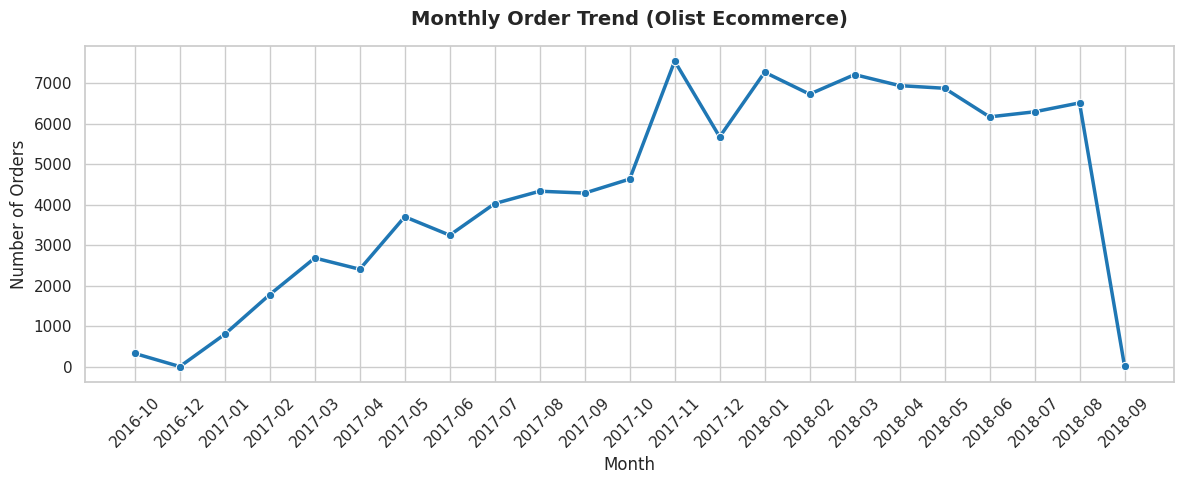

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Monthly Order Volume Trend
# Ensure order purchase timestamp is datetime
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

# Extract Year-Month
orders['order_month'] = orders['order_purchase_timestamp'].dt.to_period('M')

# Group and count monthly orders (filtering out incomplete boundary months for a cleaner story)
monthly_orders = orders.groupby('order_month').size().reset_index(name='order_count')
monthly_orders['order_month'] = monthly_orders['order_month'].astype(str)
monthly_orders = monthly_orders.sort_values('order_month').iloc[1:-1] # Trim first and last month if incomplete

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_orders, x='order_month', y='order_count', marker='o', color='#1f77b4', linewidth=2.5)
plt.title('Monthly Order Trend (Olist Ecommerce)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

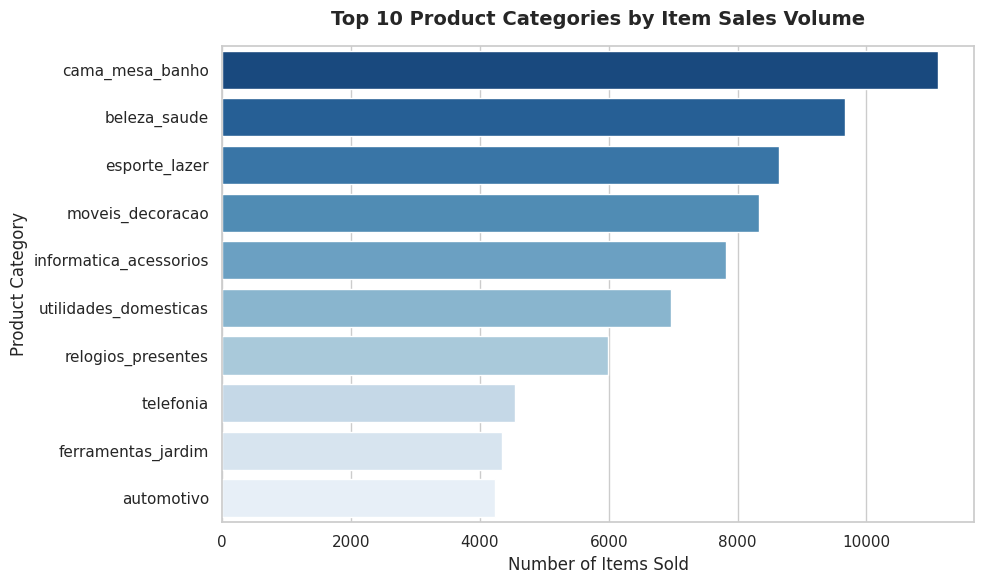

In [4]:
# 2. Top 10 Product Categories by Sales Volume
# Merge order_items with products to get categories
merged_items = pd.merge(order_items, products, on='product_id', how='left')
top_categories = merged_items['product_category_name'].value_counts().head(10).reset_index()
top_categories.columns = ['product_category_name', 'sales_count']

plt.figure(figsize=(10, 6))
# We assign hue='product_category_name' and legend=False to resolve the Seaborn deprecation warning
sns.barplot(data=top_categories, x='sales_count', y='product_category_name', hue='product_category_name', palette='Blues_r', legend=False)
plt.title('Top 10 Product Categories by Item Sales Volume', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Items Sold', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.tight_layout()
plt.show()

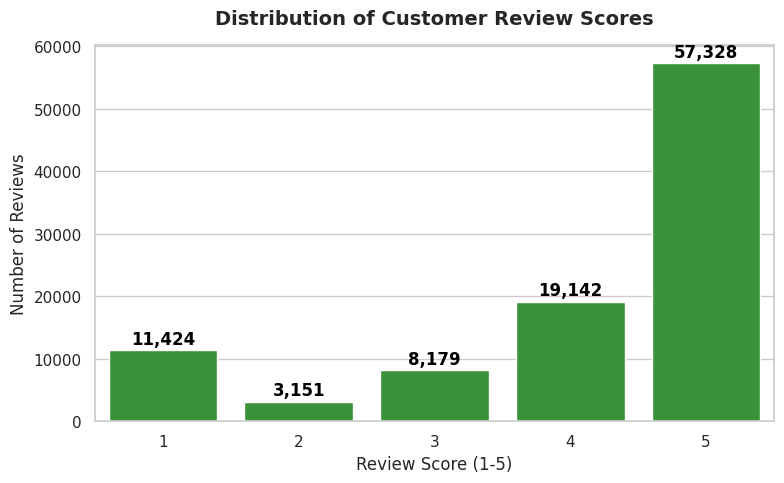

In [5]:
# 3. Distribution of Customer Review Scores
review_distribution = reviews['review_score'].value_counts().sort_index().reset_index()
review_distribution.columns = ['review_score', 'count']

plt.figure(figsize=(8, 5))
sns.barplot(data=review_distribution, x='review_score', y='count', color='#2ca02c')
plt.title('Distribution of Customer Review Scores', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Review Score (1-5)', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)

# Adding value labels on top of bars for clarity
for index, row in review_distribution.iterrows():
    plt.text(index, row['count'] + 1000, f"{row['count']:,}", color='black', ha="center", fontweight='semibold')

plt.tight_layout()
plt.show()

## 📊 Preparing Power BI Teaching Datasets

In this section, we build clean, multi-dimensional dataset blueprints optimized for teaching **Data Storytelling** and data modeling in Microsoft Power BI Desktop.

### Why Two Separate Master CSVs?
Rather than forcing a massive, flattened table that causes cardinality inflation (many-to-many duplicates), we will construct two distinct Master CSVs with transparent grains:
1. **`olist_sales_master.csv`**: Granularity of **one row per order item**. This links orders, item details, products, customer location profiles, and aggregated zip coordinates.
2. **`olist_reviews_master.csv`**: Granularity of **one row per review**. This links reviews to their parental order metadata and customer states, avoiding double-counting of review items.

In [6]:
import os
import pandas as pd

# Create export directory
OUTPUT_DIR = "/content/power_bi_datasets/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Verifying Schemas, Shapes, and Keys:")
print(f"Orders columns: {list(orders.columns)}")
print(f"Order Items columns: {list(order_items.columns)}")
print(f"Products columns: {list(products.columns)}")
print(f"Customers columns: {list(customers.columns)}")
print(f"Reviews columns: {list(reviews.columns)}")
print(f"Geolocation columns: {list(geolocation.columns)}")

Verifying Schemas, Shapes, and Keys:
Orders columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_month']
Order Items columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Products columns: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
Customers columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
Reviews columns: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
Geolocation columns: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geoloca

In [7]:
# To avoid multiplying rows during geo-merges, we must deduplicate the geolocation table.
# We aggregate latitude and longitude by zip code prefix.
print("Processing and deduplicating Geolocation dataset...")
geo_dedup = geolocation.groupby('geolocation_zip_code_prefix').agg({
    'geolocation_lat': 'mean',
    'geolocation_lng': 'mean',
    'geolocation_city': 'first',
    'geolocation_state': 'first'
}).reset_index()

print(f"Original Geo rows: {len(geolocation):,} -> Deduplicated Zip-code prefixes: {len(geo_dedup):,}")

Processing and deduplicating Geolocation dataset...
Original Geo rows: 1,000,163 -> Deduplicated Zip-code prefixes: 19,015


In [8]:
# Build Master CSV 1: olist_sales_master.csv
# Granularity: One row per order item.
print("\n--- Creating olist_sales_master.csv ---")

# Join 1: Merge order_items with orders
print(f"Starting order_items count: {len(order_items):,}")
sales_master = pd.merge(order_items, orders, on='order_id', how='left')
print(f"After merging with orders: {len(sales_master):,} (Expected to match order_items row count)")

# Join 2: Merge with products
sales_master = pd.merge(sales_master, products[['product_id', 'product_category_name', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']], on='product_id', how='left')
print(f"After merging with products: {len(sales_master):,}")

# Join 3: Merge with customers
sales_master = pd.merge(sales_master, customers, on='customer_id', how='left')
print(f"After merging with customers: {len(sales_master):,}")

# Join 4: Merge with deduplicated geolocation
sales_master = pd.merge(
    sales_master,
    geo_dedup,
    left_on='customer_zip_code_prefix',
    right_on='geolocation_zip_code_prefix',
    how='left'
)
print(f"After merging with geolocation lookup: {len(sales_master):,}")

# Save to disk
sales_master_path = os.path.join(OUTPUT_DIR, "olist_sales_master.csv")
sales_master.to_csv(sales_master_path, index=False, encoding='utf-8')
print(f"Successfully saved olist_sales_master.csv to {sales_master_path}")


--- Creating olist_sales_master.csv ---
Starting order_items count: 112,650
After merging with orders: 112,650 (Expected to match order_items row count)
After merging with products: 112,650
After merging with customers: 112,650
After merging with geolocation lookup: 112,650
Successfully saved olist_sales_master.csv to /content/power_bi_datasets/olist_sales_master.csv


In [9]:
# Build Master CSV 2: olist_reviews_master.csv
# Granularity: One row per review record.
print("\n--- Creating olist_reviews_master.csv ---")

print(f"Starting reviews count: {len(reviews):,}")

# Join 1: Merge reviews with orders
reviews_master = pd.merge(reviews, orders, on='order_id', how='left')
print(f"After merging with orders: {len(reviews_master):,}")

# Join 2: Merge with customers to support geographic analysis of sentiment
reviews_master = pd.merge(reviews_master, customers, on='customer_id', how='left')
print(f"After merging with customers: {len(reviews_master):,}")

# Save to disk
reviews_master_path = os.path.join(OUTPUT_DIR, "olist_reviews_master.csv")
reviews_master.to_csv(reviews_master_path, index=False, encoding='utf-8')
print(f"Successfully saved olist_reviews_master.csv to {reviews_master_path}")


--- Creating olist_reviews_master.csv ---
Starting reviews count: 99,224
After merging with orders: 99,224
After merging with customers: 99,224
Successfully saved olist_reviews_master.csv to /content/power_bi_datasets/olist_reviews_master.csv


## Assignment


1. **Load Datasets:**
   * Open **Power BI Desktop**.
   * Select **Get Data** ➡️ **Text/CSV**.
   * Import `olist_sales_master.csv`.
   * Import `olist_reviews_master.csv`.
2. **Transform your data:**
   * Make sure BI assigns the correct data types to different columns.
2. **Inspect Relationships:**
   * Navigate to the **Model View** tab.
   * Verify that both tables are treated as independent fact tables. If you want to analyze reviews alongside product sales, link both tables on the common key `order_id` as a **1-to-Many** relationship (or keep them separate to preserve clean granularity!).
3. **Create your visuals:**
   * Pick the appropriate charts to answer the questions below. Paginate accordingly
   

---

### 👥 Group A: Sales and Product Performance

#### Question 1: Which Brazilian state generates the highest total sales volume (revenue)?
* **Caution:** Remember that `price` represents the cost of the *item line* and excludes the freight cost. To find overall customer checkout costs, you must combine `price` and `freight_value`

#### Question 2: What are the top 10 product categories by item count, and do they also generate the most revenue?


#### Question 3: How does the number of unique orders scale on a monthly trend, and is there visible seasonality?
* **Caution:** A basic count of rows will represent item counts rather than orders. Ensure you set the calculation aggregation type to **Distinct Count**!

---

### 👥 Group B: Customer Experience and Deliveries

#### Question 1: Which customer states suffer from the lowest average customer review scores?
* **Caution:** Power BI defaults to **Sum** on numeric fields. You must explicitly click the drop-down on the `review_score` field in the Values bucket and change it to **Average**.

#### Question 2: What is the overall distribution of satisfaction scores across all transactions?

#### Question 3: Is there a visible relationship between delivery delays and customer satisfaction?


Questions I Answered
### 1. Calculate total sales revenue by product
### 2. Generate a bar chart showing top 10 product categories by revenue
### 3. Compare total revenue vs total order count per category